# 06 · Which words push the detector? LIME word explanations (exploratory)

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SheridanLu/detecting-the-detector/blob/main/notebooks/06_lime_word_explanations.ipynb)

> **EXPLORATORY SIDE ANALYSIS. NOT IN OUR PRESENTATION SLIDES.** This notebook was added to show how a detector can be
> *inspected*. It uses two essays and one detector seed. It proves nothing about non-native writing in general.
>
> **WHAT IS RE-RUN, WHAT IS REPLAYED**
>
> | part | what | status |
> |---|---|---|
> | 1 | the TF-IDF + logistic-regression detectors of arm A and arm C (seed 0), trained exactly as in notebook 02 | **RE-RUN** from scratch on CPU |
> | 2 | LIME (official `lime` package) explaining each detector on two essays | **RE-RUN** on CPU |
> | 3 | comparison with the numbers archived from an earlier run on the server (`data/results/lime_words_armA.csv`) | **REPLAYED** (archived numbers are only read) |

**Goal.** A detector gives an essay one number: the probability that it is AI-written. *Which words* made that number go up or
down? **LIME** (Ribeiro et al., 2016) answers this for any detector: it deletes random words from the essay, asks the detector
for its probability each time, and fits a very simple word-by-word model to those answers. The weight of a word says
roughly "if this word is present, the probability of AI changes by about this many probability points".

| Mode | What runs | Time on a laptop CPU (Colab CPU is usually slower) | GPU |
|---|---|---|---|
| SMOKE | both detectors trained as usual; LIME with **500** samples and **3** random states; LIME-dependent comparisons are printed but not judged | about 20-45 s (most of it loading the data and training) | no |
| FAST (default) | LIME with **5,000** samples (the archived setting), **5** random states | about 20-40 s (LIME itself takes a few seconds) | no |
| FULL | same as FAST (there is nothing bigger to run) | same as FAST | no |

Credit: LIME is Ribeiro, Singh and Guestrin (2016), *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*,
KDD. Code: https://github.com/marcotcr/lime (version 0.2.0.1 here).

In [1]:
# --- Setup: find the repository (or download it on Colab) and install anything Colab does not have ---
import os, sys, time, pathlib, subprocess
T0 = time.time()
REPO_URL = "https://github.com/SheridanLu/detecting-the-detector"

def _is_repo(p):
    return (p / "ddlib" / "__init__.py").is_file() and (p / "data").is_dir()

def _locate_or_fetch():
    here = pathlib.Path.cwd().resolve()
    for p in [pathlib.Path(os.environ.get("DD_REPO", here)), here, *here.parents]:
        if _is_repo(p):
            return p                                   # mode 1: already inside the repo
    dest = pathlib.Path("/content" if os.path.isdir("/content") else here) / "detecting-the-detector"
    if not _is_repo(dest) and not dest.exists():       # mode 2: git clone (token optional, for a private repo)
        tok = os.environ.get("GH_TOKEN")
        try:
            from google.colab import userdata
            tok = userdata.get("GH_TOKEN") or tok
        except Exception:
            pass
        url = REPO_URL.replace("https://", f"https://x-access-token:{tok}@") if tok else REPO_URL
        subprocess.run(["git", "clone", "--depth", "1", "-q", url, str(dest)], env=dict(os.environ, GIT_TERMINAL_PROMPT="0"))
        if tok and dest.exists():
            subprocess.run(["git", "-C", str(dest), "remote", "set-url", "origin", REPO_URL])   # token not kept on disk
    if _is_repo(dest):
        return dest
    return None                                        # mode 3 (zip upload) is handled by ddlib below

root = _locate_or_fetch()
if root is None:
    # Zip fallback: needs the small ddlib/paths.py helper, which we cannot import yet, so do it here.
    print("Could not find or clone the repository.\n"
          "Fix 1: add a Colab secret GH_TOKEN (key icon, left sidebar) with read access, allow notebook access, re-run.\n"
          f"Fix 2: download the repo as a zip ({REPO_URL} > Code > Download ZIP) and upload it when asked.")
    from google.colab import files
    import zipfile
    up = files.upload()
    zipfile.ZipFile(next(k for k in up if k.endswith(".zip"))).extractall("/content")
    root = next(p.parent.parent for p in pathlib.Path("/content").glob("*/ddlib/__init__.py") if _is_repo(p.parent.parent))
sys.path.insert(0, str(root))
os.chdir(root)                                         # all paths below are relative to the repo root

_req = [l.strip() for l in open("requirements-colab.txt") if l.strip() and not l.startswith("#")]
try:
    import lime                                        # Colab does not preinstall it: install only if missing
except ImportError:
    _req += [l.strip() for l in open("requirements-nb06.txt") if l.strip() and not l.startswith("#")]
if _req:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_req], check=True)

from ddlib import get_repo
REPO = get_repo()
print("Python", sys.version.split()[0])

Repository found. Data folder present: True
Python 3.12.16


## Configuration

In [2]:
# --- CONFIG ---------------------------------------------------------------------------------------
# MODE = "SMOKE" (seconds; used for automated testing), "FAST" (default) or "FULL" (identical to FAST).
# Change the string below to switch. (The DD_MODE environment variable is only used by automated tests.)
MODE = os.environ.get("DD_MODE", "FAST").upper()
assert MODE in ("SMOKE", "FAST", "FULL"), MODE
NUM_SAMPLES = 500 if MODE == "SMOKE" else 5000                  # LIME: how many perturbed copies of the essay (archived run: 5000)
RANDOM_STATES = [42, 0, 1] if MODE == "SMOKE" else [42, 0, 1, 2, 3]   # the first one (42) is the main run, as in the archived run
NUM_FEATURES = 10                                               # the 10 strongest words are reported
SEED = 0                                                        # detector seed (seed 0 of arms A and C)
OVERLAP_PASS = 8                                                # PASS if at least 8 of the 10 words agree with the archived run
JUDGE_LIME = MODE != "SMOKE"                                    # SMOKE uses 500 samples, so LIME-dependent comparisons are not judged
FIG_DIR = pathlib.Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"MODE = {MODE} | LIME samples: {NUM_SAMPLES} | random states: {RANDOM_STATES} | top words: {NUM_FEATURES} | detector seed: {SEED}")

MODE = FAST | LIME samples: 5000 | random states: [42, 0, 1, 2, 3] | top words: 10 | detector seed: 0


## 1. The two detectors (re-trained here)
Exactly the detector of notebook 02 (settings copied from `a40/train_lr.py`, no tuning): TF-IDF over single words and word pairs
(`ngram_range=(1, 2)`, `max_features=20000`, `min_df=2`) followed by `LogisticRegression(max_iter=2000, random_state=0)`.
* **Arm A**: trained on 4,000 native essays (PERSUADE 2.0) against 4,000 AI essays (run `seed0_A_n4000`).
* **Arm C**: trained on 2,000 native + 2,000 exam-style non-native essays (FCE, Write & Improve) against the same AI essays (follow-up set `seed0_C`).

Both take only a few seconds on a CPU.

In [3]:
import textwrap, importlib.metadata
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from ddlib import data as D, metrics as M, lime_words as LW
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
print("lime version:", importlib.metadata.version("lime"))

t = time.time()
pool = D.load_pool(cleaned=True); manifests = D.load_manifests()
DET = {}
for arm in "AC":
    t1 = time.time()
    DET[arm], n_train = LW.train_arm(arm, SEED, pool, manifests)
    print(f"arm {arm}: {D.run_name(arm, SEED)} trained on {n_train} essays in {time.time() - t1:.1f} s")
print(f"loading + training: {time.time() - t:.0f} s")

lime version: 0.2.0.1


arm A: seed0_A_n4000 trained on 8000 essays in 2.4 s


arm C: seed0_C trained on 8000 essays in 2.1 s
loading + training: 9 s


## 2. The two essays
* **TOEFL essay 84** (`TOEFL_real_91#84`): written by a non-native student, 107 words, cleaned with `ddlib.clean()`. In notebook 01 it is
  the example that all seven commercial detectors flagged.
* **College application essay 23** (`CollegeEssay_real_70#23`): written by a native speaker. It is long, so we keep only its **first
  98 words** (cut with a plain whitespace word split after cleaning) to make it about as long as the TOEFL essay.

The detector sees exactly these texts. Both are human-written.

In [4]:
ESS = LW.get_essays()
for k, e in ESS.items():
    print(f"[{k}] {e['title']}: {e['n_words']} words (full essay: {e['n_words_full']} words)")
    print(textwrap.fill(e["text"], 120), "\n")
rows = [dict(essay=k, **{f"P(AI) arm {arm}": DET[arm].predict_proba([e["text"]])[0, 1] for arm in "AC"}) for k, e in ESS.items()]
print("Probability of AI given by each detector (flagged as AI if 0.5 or more):")
display(pd.DataFrame(rows).set_index("essay").round(3))

[toefl84] TOEFL essay, non-native writer: 107 words (full essay: 107 words)
I believe the most important decision I've ever made would be going to engineering school. Being an engineer is
something I've always been looking forward to since I was a little kid. It will allow me to bring out my creativity in
my daily work, it will make the work a lot more fun. And I'd like it if I can build something that would last much
longer even after I am gone, and seeing people benefit from my design will definitely give me great satisfaction. So
going to engineering school really is a brand new start of my life. That's why it's so important to me. 

[college23_excerpt] College application essay, native writer (first 98 words): 98 words (full essay: 499 words)
Gazing up at the starry sky, I see Cygnus, Hercules, and Pisces, remnants of past cultures. I listen to waves crash on
the beach, the forces of nature at work. Isn't it odd how stars are flaming spheres and electrical impulses make beings
sent

,P(AI) arm A,P(AI) arm C
essay,,
toefl84,0.445,0.070
college23_excerpt,0.816,0.484


## 3. LIME: which words matter?
For each detector and essay we call the official package:
`LimeTextExplainer(class_names=["human", "AI"], random_state=42).explain_instance(text, detector.predict_proba, num_features=10, num_samples=NUM_SAMPLES, labels=(1,))`
(label 1 = the probability of **AI**). A **positive** weight means the word pushes toward AI; a **negative** weight pushes toward human.
Weights are in probability points (0.10 = 10 points). LIME treats the essay as a bag of words: every occurrence of a word
shares one weight, and small and capital letters count as different words.
The **local R²** (`explanation.score`) says how well LIME's simple word model matches the detector around this essay (1 = perfectly).

In [5]:
RES = {}                                    # (arm, essay) -> LIME result with random_state RANDOM_STATES[0]
t = time.time()
for arm in "AC":
    for k, e in ESS.items():
        t1 = time.time()
        RES[(arm, k)] = LW.explain(DET[arm], e["text"], random_state=RANDOM_STATES[0], num_samples=NUM_SAMPLES, num_features=NUM_FEATURES)
        print(f"LIME arm {arm}, {k}: {time.time() - t1:.1f} s, local R^2 = {RES[(arm, k)]['r2']:.3f}")
print(f"LIME total: {time.time() - t:.0f} s")
for arm in "AC":
    tab = pd.DataFrame({"rank": range(1, NUM_FEATURES + 1)}).set_index("rank")
    for k in ESS:
        w = RES[(arm, k)]["weights"]
        tab[f"{k}: word"] = [a for a, _ in w]; tab[f"{k}: weight"] = [b for _, b in w]
    print(f"\nArm {arm}: the 10 strongest words (weight > 0 pushes toward AI, < 0 toward human)")
    display(tab.round(3))

LIME arm A, toefl84: 0.2 s, local R^2 = 0.666


LIME arm A, college23_excerpt: 0.2 s, local R^2 = 0.638


LIME arm C, toefl84: 0.2 s, local R^2 = 0.698


LIME arm C, college23_excerpt: 0.2 s, local R^2 = 0.736
LIME total: 1 s

Arm A: the 10 strongest words (weight > 0 pushes toward AI, < 0 toward human)


,toefl84: word,toefl84: weight,college23_excerpt: word,college23_excerpt: weight
rank,,,,
1,school,-0.102,of,0.041
2,would,-0.072,all,-0.036
3,going,-0.068,support,0.030
4,people,-0.056,up,-0.020
5,will,-0.052,planet,-0.019
6,important,0.040,they,-0.018
7,engineering,0.032,world,-0.017
8,ve,0.027,waves,0.013
9,benefit,0.020,nature,0.012



Arm C: the 10 strongest words (weight > 0 pushes toward AI, < 0 toward human)


,toefl84: word,toefl84: weight,college23_excerpt: word,college23_excerpt: weight
rank,,,,
1,my,-0.097,of,0.087
2,going,-0.029,all,-0.074
3,school,-0.024,my,-0.052
4,will,-0.022,support,0.049
5,people,-0.022,very,-0.047
6,me,-0.021,at,-0.044
7,am,-0.020,up,-0.032
8,decision,0.019,to,0.030
9,benefit,0.018,that,0.025


## 4. The word-shaded picture
Red = the word pushes toward AI, blue-grey = toward human; the darker, the stronger. The number after a word is its weight in probability points.
The header shows P(AI) of both detectors. **First figure: arm A's weights** (this is the picture of the detector that saw only native essays);
**second figure: the same for arm C**. Files are saved in `outputs/figures/` (not tracked by git).

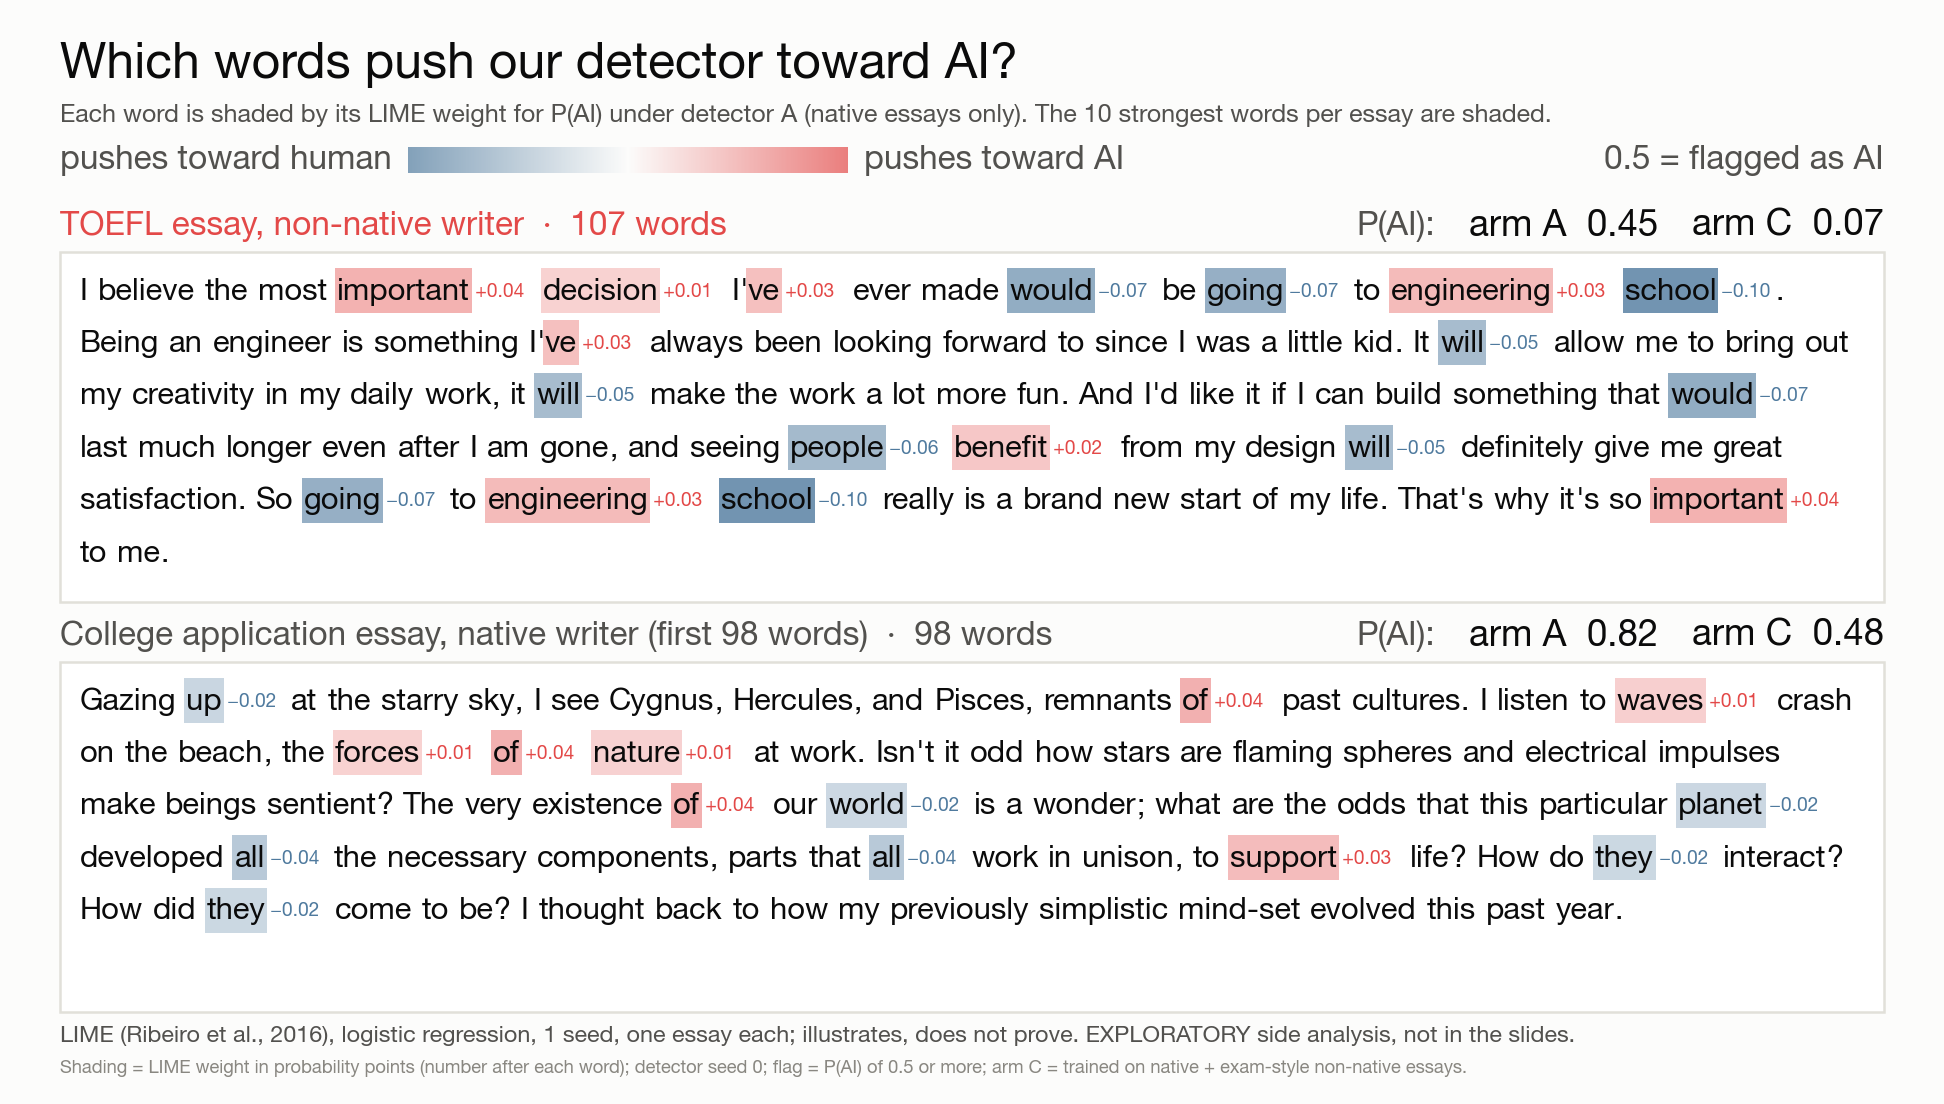

saved outputs/figures/nb06_lime_words_armA.png


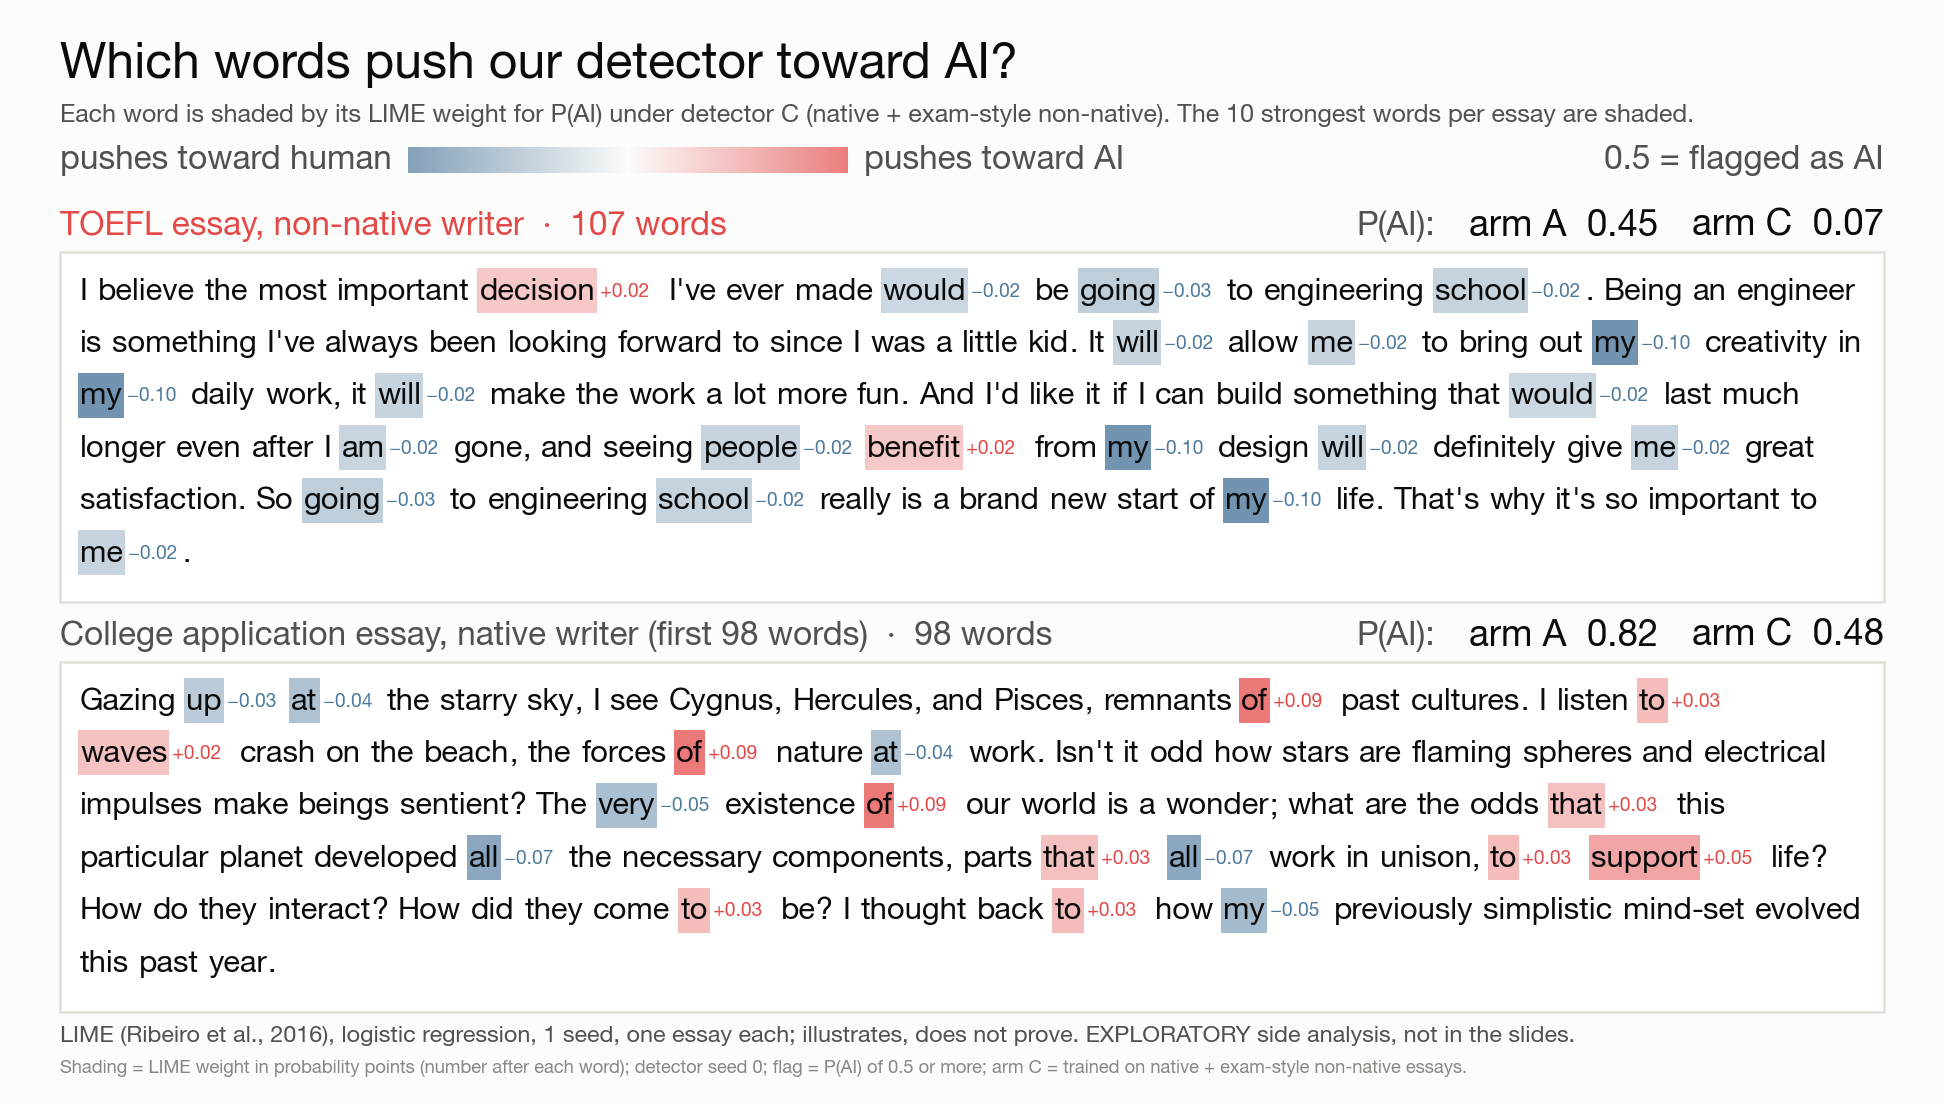

saved outputs/figures/nb06_lime_words_armC.png


In [6]:
def cards_for(arm):
    return [dict(title=e["title"], color=(LW.C_AI if k == "toefl84" else LW.INK2), text=e["text"], n_words=e["n_words"],
                 p_a=RES[("A", k)]["p_ai"], p_c=RES[("C", k)]["p_ai"], weights=dict(RES[(arm, k)]["weights"])) for k, e in ESS.items()]
for arm in "AC":
    fig = LW.draw_word_figure(cards_for(arm), arm)
    out = FIG_DIR / f"nb06_lime_words_arm{arm}.png"
    fig.savefig(out, dpi=120, facecolor=LW.SURF)
    plt.show(); plt.close(fig)
    print("saved", out)

## 5. Comparison with the archived run
`data/results/lime_words_armA.csv` holds the numbers produced earlier on the server from the same recipe (same code path: detectors
retrained on seed 0, LIME 0.2.0.1, `random_state=42`, 5,000 samples, 10 words). It contains the probabilities of **both** arms but the word weights
of **arm A only**, so arm C is compared by probability only.

PASS / FAIL rules (fixed in advance of the run, not tuned afterwards):
* **Probability of AI**: within 0.02 of the archived value. The detectors are re-trained, so they are not bit-identical to the original.
* **Top-10 words (arm A)**: PASS if **at least 8 of the 10 words** are the same as in the archived list. With the same recipe we expect
  all 10; random agreement would be about 0 or 1, so 8 is a loose bound that still means "the same story". If the overlap is lower we report it as FAIL.
* **Local R²**: within 0.05 of the archived value (a tolerance we chose; LIME's sampling is random).
* **Text**: the essay we explain is character-for-character the archived text.
* Also checked: the re-trained detectors reproduce the saved predictions of the original run (`data/preds/lr/`) for the full TOEFL essay.

In SMOKE mode LIME uses only 500 samples, so the LIME-dependent lines (top-10, R²) are printed as information and **not judged**.

In [7]:
ref = pd.read_csv("data/results/lime_words_armA.csv", keep_default_na=False)
refE = ref[ref.row_type == "essay"].set_index("essay")
refW = {k: [(r.word, float(r.lime_weight_armA)) for r in ref[(ref.essay == k) & (ref.row_type == "word")].itertuples()] for k in ESS}
CMP = []
def add(check, got, archived, tol, quoted=None):
    c = M.compare(check, got, archived, tol)
    if quoted is not None and abs(archived - quoted) > 0.0006: c["result"] = "FAIL"       # the CSV must agree with the rounded number we quote
    CMP.append(c)

# (a) text, probabilities
for k, e in ESS.items():
    CMP.append(dict(check=f"{k}: explained text identical to archived text", recomputed=float(e["text"] == refE.loc[k, "text"]), archived=1.0, tolerance=0, result="PASS" if e["text"] == refE.loc[k, "text"] else "FAIL"))
quoted = {("A", "toefl84"): 0.446, ("A", "college23_excerpt"): 0.816, ("C", "toefl84"): 0.070, ("C", "college23_excerpt"): 0.484}
for (arm, k), q in quoted.items():
    arch = float(refE.loc[k, f"p_ai_arm{arm}"])
    add(f"P(AI) arm {arm}, {k} (quoted {q})", RES[(arm, k)]["p_ai"], arch, 0.02, quoted=q)
# (b) the full TOEFL essay against the saved predictions of the original run
full84 = D.load_exams(cleaned=True).set_index("essay_id").loc["TOEFL_real_91#84", "text"]
for arm in "AC":
    sv = D.load_preds("LR", arm, SEED, 4000)
    arch = float(sv[sv.essay_id == "TOEFL_real_91#84"].score.iloc[0])
    add(f"arm {arm}: full TOEFL essay 84, re-trained vs saved prediction in data/preds/lr", float(DET[arm].predict_proba([full84])[0, 1]), arch, 0.02)
# (c) LIME-dependent: top-10 overlap and R^2 (arm A only; the archive has no arm C weights)
LIME_ROWS = []
for k in ESS:
    ov = LW.top_overlap(RES[("A", k)]["weights"], refW[k])
    r2a = float(refE.loc[k, "lime_local_R2_armA"]); r2 = RES[("A", k)]["r2"]
    shared = dict(RES[("A", k)]["weights"]); sw = [w for w, _ in refW[k] if w in shared]
    same_sign = all(np.sign(shared[w]) == np.sign(dict(refW[k])[w]) for w in sw)
    maxdiff = max(abs(shared[w] - dict(refW[k])[w]) for w in sw)
    LIME_ROWS.append(dict(essay=k, overlap=f"{ov}/10", same_sign_on_shared=same_sign, max_weight_diff=round(maxdiff, 4), R2_rerun=round(r2, 3), R2_archived=round(r2a, 3)))
    if JUDGE_LIME:
        CMP.append(dict(check=f"arm A, {k}: top-10 words shared with archived list (need >= {OVERLAP_PASS})", recomputed=float(ov), archived=10.0, tolerance=10 - OVERLAP_PASS, result="PASS" if ov >= OVERLAP_PASS else "FAIL"))
        add(f"arm A, {k}: LIME local R^2", r2, r2a, 0.05)
cmp = pd.DataFrame(CMP)
display(cmp.round(4))
for r in cmp.itertuples():
    print(f"{r.result}  {r.check}: re-run {r.recomputed:.3f} vs archived {r.archived:.3f} (tolerance {r.tolerance})")
print("\nInformation (arm A vs archived word list):")
display(pd.DataFrame(LIME_ROWS).set_index("essay"))
if not JUDGE_LIME:
    print("SMOKE: top-10 overlap and R^2 are shown above but NOT judged (500 samples instead of 5000).")
N_PASS, N_FAIL = int((cmp.result == "PASS").sum()), int((cmp.result == "FAIL").sum())
print(f"\nCOMPARISON SUMMARY: {N_PASS} PASS, {N_FAIL} FAIL (mode {MODE}). Arm C top words have no archived reference: NEW (not archived, no PASS/FAIL).")

,check,recomputed,archived,tolerance,result
0,toefl84: explained text identical to archived ...,1.0000,1.0000,0.00,PASS
1,college23_excerpt: explained text identical to...,1.0000,1.0000,0.00,PASS
2,"P(AI) arm A, toefl84 (quoted 0.446)",0.4452,0.4459,0.02,PASS
3,"P(AI) arm A, college23_excerpt (quoted 0.816)",0.8155,0.8162,0.02,PASS
4,"P(AI) arm C, toefl84 (quoted 0.07)",0.0703,0.0704,0.02,PASS
5,"P(AI) arm C, college23_excerpt (quoted 0.484)",0.4837,0.4839,0.02,PASS
6,"arm A: full TOEFL essay 84, re-trained vs save...",0.4452,0.4459,0.02,PASS
7,"arm C: full TOEFL essay 84, re-trained vs save...",0.0703,0.0704,0.02,PASS
8,"arm A, toefl84: top-10 words shared with archi...",10.0000,10.0000,2.00,PASS
9,"arm A, toefl84: LIME local R^2",0.6662,0.6686,0.05,PASS


PASS  toefl84: explained text identical to archived text: re-run 1.000 vs archived 1.000 (tolerance 0.0)
PASS  college23_excerpt: explained text identical to archived text: re-run 1.000 vs archived 1.000 (tolerance 0.0)
PASS  P(AI) arm A, toefl84 (quoted 0.446): re-run 0.445 vs archived 0.446 (tolerance 0.02)
PASS  P(AI) arm A, college23_excerpt (quoted 0.816): re-run 0.816 vs archived 0.816 (tolerance 0.02)
PASS  P(AI) arm C, toefl84 (quoted 0.07): re-run 0.070 vs archived 0.070 (tolerance 0.02)
PASS  P(AI) arm C, college23_excerpt (quoted 0.484): re-run 0.484 vs archived 0.484 (tolerance 0.02)
PASS  arm A: full TOEFL essay 84, re-trained vs saved prediction in data/preds/lr: re-run 0.445 vs archived 0.446 (tolerance 0.02)
PASS  arm C: full TOEFL essay 84, re-trained vs saved prediction in data/preds/lr: re-run 0.070 vs archived 0.070 (tolerance 0.02)
PASS  arm A, toefl84: top-10 words shared with archived list (need >= 8): re-run 10.000 vs archived 10.000 (tolerance 2.0)
PASS  arm A,

,overlap,same_sign_on_shared,max_weight_diff,R2_rerun,R2_archived
essay,,,,,
toefl84,10/10,True,0.0005,0.666,0.669
college23_excerpt,10/10,True,0.0020,0.638,0.644



COMPARISON SUMMARY: 12 PASS, 0 FAIL (mode FAST). Arm C top words have no archived reference: NEW (not archived, no PASS/FAIL).


## 6. Is the explanation stable? Repeat LIME with different random states
LIME is random (it deletes random words), so two runs can give different word lists. We repeat each explanation with several `random_state`
values (the first, 42, is the main run above) and report: the local R² of every run, how many of the 10 words each run shares with the main run,
the average overlap between all pairs of runs, and how many words appear in **every** run.

In [8]:
STAB, ALLRUNS = [], {}
t = time.time()
for arm in "AC":
    for k, e in ESS.items():
        runs = {RANDOM_STATES[0]: RES[(arm, k)]}
        for rs in RANDOM_STATES[1:]:
            runs[rs] = LW.explain(DET[arm], e["text"], random_state=rs, num_samples=NUM_SAMPLES, num_features=NUM_FEATURES)
        ALLRUNS[(arm, k)] = runs
        sets = {rs: {w for w, _ in r["weights"]} for rs, r in runs.items()}
        pair = [len(sets[a] & sets[b]) for i, a in enumerate(sets) for b in list(sets)[i + 1:]]
        r2s = [r["r2"] for r in runs.values()]
        base = sets[RANDOM_STATES[0]]
        STAB.append({"arm": arm, "essay": k,
                     "R2 min / mean / max": f"{min(r2s):.2f} / {np.mean(r2s):.2f} / {max(r2s):.2f}",
                     "overlap with state 42 (other states)": ", ".join(f"{len(base & sets[rs])}/10" for rs in RANDOM_STATES[1:]),
                     "mean pairwise overlap": f"{np.mean(pair):.1f}/10",
                     "words in every run": len(set.intersection(*sets.values()))})
print(f"{len(RANDOM_STATES)} random states x 2 arms x 2 essays: {time.time() - t:.0f} s")
display(pd.DataFrame(STAB).set_index(["arm", "essay"]))
for (arm, k), runs in ALLRUNS.items():
    sign = {}
    for r in runs.values():
        for w, v in r["weights"]: sign.setdefault(w, set()).add(np.sign(v))
    flips = sorted(w for w, s in sign.items() if len(s) > 1)
    print(f"arm {arm}, {k}: words whose sign differs between runs: {flips if flips else 'none'}")

5 random states x 2 arms x 2 essays: 3 s


R2 min / mean / max overlap with state 42 (other states) mean pairwise overlap  words in every run
arm essay                                                                                                               
A   toefl84            0.67 / 0.70 / 0.72              10/10, 9/10, 9/10, 9/10                9.4/10                   9
    college23_excerpt  0.64 / 0.65 / 0.66           10/10, 10/10, 10/10, 10/10               10.0/10                  10
C   toefl84            0.70 / 0.71 / 0.72               8/10, 9/10, 8/10, 8/10                8.6/10                   7
    college23_excerpt  0.74 / 0.74 / 0.75           10/10, 10/10, 10/10, 10/10               10.0/10                  10

arm A, toefl84: words whose sign differs between runs: none
arm A, college23_excerpt: words whose sign differs between runs: none
arm C, toefl84: words whose sign differs between runs: none
arm C, college23_excerpt: words whose sign differs between runs: none


## 7. What can we honestly say?
Read the numbers printed above, with these limits in mind.

* **Under arm A the native college essay gets the higher P(AI).** The detector trained on native essays only gives the native college
  excerpt about 0.82 and the non-native TOEFL essay about 0.45. So in this pair the detector is *not* more suspicious of the non-native essay. (Notebook 01 and
  the other notebooks measure the bias over all 91 TOEFL essays; one pair says nothing about that.)
* **Arm C gives lower numbers for both essays** (about 0.07 and 0.48): adding exam-style non-native writing to the training data lowered the probability of AI
  for both essays here, a lot for the TOEFL essay. Again one pair of essays.
* **The strongest words are everyday function words** such as *will*, *would*, *going*, *of*, *all*. They are not exotic vocabulary. In the TOEFL essay the five strongest words
  have negative weights: they pull the probability *down*, not up. A word list like this tells us what the logistic regression has learned to associate with AI or human
  text in its training data; it does not say that the author used a "wrong" word.
* **The weights are small.** The largest is about 0.10 (ten probability points). The probability is the sum of many small pushes, none of which decides the flag.
* **The local fit is only moderate.** The R² of about 0.6 to 0.7 means LIME's word-by-word summary explains part, not all, of how the detector reacts to deleting words
  (the detector also reacts to word pairs and to the interplay of words). Treat the word list as a hint.
* **LIME is random**; section 6 shows how much the top-10 list moves between random states (for arm C's TOEFL explanation 8 to 9 of the 10 words stay the same; no word changes sign).
* **One seed, one essay each.** Different detector seeds or different essays could give a different picture.

**Bottom line.** This notebook illustrates *how a detector can be inspected* word by word. It proves nothing about how detectors treat non-native writing in general;
that question is answered with all 91 TOEFL essays and several detector families in notebooks 01 to 05.

# Limits and what is not verified
* Exploratory, not in the slides; two essays, detector seed 0, one LIME setting (10 words, 5,000 samples).
* Arm C word weights have no archived reference, so only their probabilities are checked against the archive.
* The TOEFL probability is for the full essay (107 words); the college probability is for the 98-word excerpt only, not for the whole essay.
* Tested locally on a laptop CPU (SMOKE and FAST). **Not run on a real Colab runtime**; the times above are laptop times.

# References
* Ribeiro, M. T., Singh, S., Guestrin, C. (2016). "Why Should I Trust You?": Explaining the Predictions of Any Classifier. KDD 2016.
* LIME package: https://github.com/marcotcr/lime (version 0.2.0.1).

In [9]:
print("=" * 100)
print(f"COMPARISON with the archived LIME run: {N_PASS} PASS, {N_FAIL} FAIL (mode {MODE})")
print("=" * 100)
print(f"Notebook finished in {time.time() - T0:.0f} s (mode {MODE}, LIME samples {NUM_SAMPLES}, {len(RANDOM_STATES)} random states).")

COMPARISON with the archived LIME run: 12 PASS, 0 FAIL (mode FAST)
Notebook finished in 16 s (mode FAST, LIME samples 5000, 5 random states).
